# 13 – Dashboard: die Karte im Browser

**Ziel.** Aus den GeoPackages von Notebook 12 **eine HTML-Datei** bauen: eine Karte zum Anschauen und Suchen. Sie zeigt, welche Plätze die Methode zählt, welche von Hand erfassten Felder sie erkennt oder übersieht und wo sie zusätzlich Parkfläche meldet. Umschalten lassen sich das Luftbild (Frühjahr 2021, Sommer 2024/25) und die Auflösung (5 cm, 10 cm). Die Ergebnisse lassen sich als GeoPackage herunterladen. Eine Legende erklärt jedes Zeichen in Alltagssprache: Wer die Daten in einem GIS verwenden will, soll die Karte lesen können, ohne das Projekt zu kennen.

**Warum.** Tabellen zeigen, wie gut die Methode im Mittel zählt. Wer eine bestimmte Strasse ansehen oder die Daten in einem GIS weiterverwenden will, braucht die Karte und die Dateien.

**Was das Dashboard nicht zeigt.** Keine Kennzahlen: Die stehen in Notebook 10. Und es ist keine Prüfung: In den Lernblöcken kennt das Netz die Stellen (`01b`, Abschnitt 11.3, K2). Das steht im Dashboard an vier Stellen: im Hinweis unter den Schaltern, in der Legende, in der Fusszeile und unter «Über diese Karte».

**Gerechnet wird hier nichts Neues.** Das Notebook liest die Dateien aus Notebook 12, rechnet die Koordinaten für die Webkarte um und setzt alles in die Vorlage `dashboard_vorlage.html` ein.

**Eingaben:** `ergebnisse/dashboard/daten/parkplaetze_{Lauf}.gpkg` und `ergebnisse/karte_zusammenfassung.csv` (Notebook 12), `gebiet.geojson` (Notebook 00), die amtlichen Punkte beider Jahre, `auswertung_laeufe.csv` (Notebook 10, nur für einen Satz im Dashboard), `CITATION.cff` (Versionsnummer), die Vorlage `notebooks/dashboard_vorlage.html`.
**Ausgaben:** `ergebnisse/dashboard/dashboard.html`, Abbildung `13_vorschau.png`.

In [1]:
import datetime                    # Datum des Standes
import json                        # Einstellungen lesen; Daten in die HTML-Datei schreiben
from pathlib import Path           # Pfade zusammensetzen

ROOT = Path.cwd().parent                             # Projektordner (eine Ebene über notebooks/)
ROH = ROOT / "daten" / "roh"                         # Rohdaten (werden nie verändert)
VERARB = ROOT / "daten" / "verarbeitet"              # abgeleitete Daten
ERG = ROOT / "ergebnisse"                            # Ergebnisse
ABB = ERG / "abbildungen"                            # Abbildungen
DASH = ERG / "dashboard"                             # Ordner des Dashboards
DATEN = DASH / "daten"                               # GeoPackages aus Notebook 12

EINST = json.loads((ROOT / "einstellungen.json").read_text(encoding="utf-8"))   # Einstellungen früherer Notebooks
CRS, KREISE, VERSUCHE, AUFLOESUNGEN_CM = EINST["CRS"], EINST["KREISE"], EINST["VERSUCHE"], EINST["AUFLOESUNGEN_CM"]

import numpy as np                 # Rechnen
import pandas as pd                # Tabellen
import geopandas as gpd            # Tabellen mit Geometrie
import matplotlib.pyplot as plt    # Abbildung
import rasterio                    # Luftbild für die Vorschau lesen
from rasterio.merge import merge   # Ausschnitt aus mehreren Bilddateien zusammensetzen
from shapely.geometry import Polygon   # Fläche aus Umriss und Löchern

**Einstellungen dieses Schritts.**

| Einstellung | Wert | Bedeutung |
| --- | --- | --- |
| `WGS` | EPSG:4326 | Längen- und Breitengrad: das Koordinatensystem der Webkarte |
| `GLAETTEN_M` | 0,15 m | Für die Webkarte werden die Umrisse der Flächen um höchstens 15 cm vereinfacht, damit die Datei klein bleibt. Das betrifft nur die Anzeige: Die GeoPackages enthalten die genauen Umrisse |
| `LOCH_M2` | 0,25 m² | Löcher in einer Fläche, die kleiner sind (meist einzelne Pixel), werden für die Anzeige geschlossen |
| `WMS` | zwei Ebenen | Namen der Luftbilder beim Kartendienst des Kantons Zürich (dort nachgesehen am 27.11.2026) |
| `FARBEN` | drei Farben | Farben des Vergleichs für die Vorschau in Abschnitt 5: grün = stimmt überein, gelb = übersehen, violett = zusätzlich gemeldet. Es sind dieselben wie in der Vorlage. Am 27.11.2026 mit einem Prüfskript für Farbpaletten geprüft: Alle drei lassen sich auch bei Rot-Grün-Schwäche unterscheiden |

In [2]:
WGS = "EPSG:4326"
GLAETTEN_M = 0.15
LOCH_M2 = 0.25
WMS = {"A": "ortho_w_2021", "B": "ortho_s_2024"}                     # Frühjahr 2021/22 und Sommer 2024/25
AMTLICH_NAME = {"A": "amtliche Parkplätze 2021", "B": "amtliche Parkplätze 2025"}   # Beschriftung im Dashboard; die genauen Quellen stehen dort unter "Quellen"
FARBEN = {"passt": "#00b894", "fehlt": "#f2a600", "extra": "#c86bfa"}       # grün, gelb, violett
LAEUFE = [f"{versuch}_{cm}cm" for versuch in VERSUCHE for cm in AUFLOESUNGEN_CM]
print("Läufe:", LAEUFE)

Läufe: ['A_5cm', 'A_10cm', 'B_5cm', 'B_10cm']


## 1. Was Notebook 12 geliefert hat

**Schritt 1: ein GeoPackage ansehen.** Jede Datei hat vier Ebenen. `gpd.read_file(..., layer=...)` liest eine davon.

Vorher: vier Dateien → nachher: wir wissen, was in jeder Ebene steht.

In [3]:
EBENEN = ["gemeldete_flaechen", "plaetze", "ausschnitte", "felder_ground_truth"]
beispiel = {ebene: gpd.read_file(DATEN / "parkplaetze_A_5cm.gpkg", layer=ebene) for ebene in EBENEN}
for ebene, tabelle in beispiel.items():
    print(f"{ebene:20s} {len(tabelle):5d} Zeilen | Spalten: {[spalte for spalte in tabelle.columns if spalte != 'geometry']}")

gemeldete_flaechen     926 Zeilen | Spalten: ['teil', 'kachel', 'flaeche_m2', 'tiefe_m', 'klasse', 'aequivalente', 'gruppe', 'plaetze', 'bestaetigt']
plaetze               2700 Zeilen | Spalten: ['kachel', 'gruppe', 'status', 'platz', 'flaeche_m2']
ausschnitte            691 Zeilen | Spalten: ['kachel', 'block', 'gruppe', 'gezaehlt', 'aequivalente', 'aeq_kleinflaechen', 'sichtbar_ground_truth']
felder_ground_truth   3226 Zeilen | Spalten: ['id', 'kachel', 'gruppe', 'form', 'klasse', 'strassenraum', 'kategorie', 'x', 'y', 'anteil_gemeldet', 'status']


## 2. Für die Webkarte umrechnen

**Worum es geht.** Die GeoPackages stehen in Schweizer Landeskoordinaten (LV95, Meter). Eine Webkarte rechnet mit Längen- und Breitengrad (WGS84). Die Funktion rechnet eine Tabelle um und macht daraus GeoJSON, das Format, das die Karte im Browser versteht.

Sechs Nachkommastellen eines Grades sind rund 10 cm. Mehr Stellen machten die Datei nur grösser.

In [4]:
def als_geojson(tabelle, spalten):
    # Rechnet eine Tabelle in WGS84 um und gibt sie als GeoJSON zurück (nur die genannten Spalten)
    wgs = tabelle[spalten + ["geometry"]].to_crs(WGS)
    wgs["geometry"] = wgs.geometry.set_precision(1e-6, mode="pointwise")   # jede Ecke auf 6 Nachkommastellen runden (rund 10 cm)
    return json.loads(wgs.to_json(drop_id=True))

probe = als_geojson(beispiel["plaetze"].head(1), ["status", "platz", "flaeche_m2", "gruppe"])
print(json.dumps(probe["features"][0], ensure_ascii=False))

{"type": "Feature", "properties": {"status": "bestätigt", "platz": "1 von 4", "flaeche_m2": 51.66, "gruppe": "lernen"}, "geometry": {"type": "Point", "coordinates": [8.547723, 47.367789]}}


**Schritt 2: die Flächen für die Anzeige vereinfachen.** Eine gemeldete Fläche folgt den Pixeln: Ihr Rand ist eine Treppe, und sie hat oft viele winzige Löcher. Das ergibt Hunderte von Ecken je Fläche und eine sehr grosse Datei. Für die **Anzeige** schliessen wir Löcher unter 0,25 m² und glätten den Umriss um höchstens 15 cm. Die Zahlen (Fläche, Platz-Äquivalente, Plätze) bleiben die der genauen Fläche, und im GeoPackage steht der genaue Umriss.

In [5]:
def fuer_anzeige(flaeche):
    # Schliesst kleine Löcher und glättet den Umriss (nur für die Webkarte)
    grosse_loecher = [loch for loch in flaeche.interiors if Polygon(loch).area >= LOCH_M2]
    return Polygon(flaeche.exterior, grosse_loecher).simplify(GLAETTEN_M)

genau = beispiel["gemeldete_flaechen"].geometry
einfach = genau.apply(fuer_anzeige)
print(f"{len(genau)} Flächen des Laufs A_5cm für die Anzeige vereinfacht")

926 Flächen des Laufs A_5cm für die Anzeige vereinfacht


**Kontrolle: Wie viel einfacher ist es geworden, und bleibt die Fläche gleich?** Wir zählen die Ecken vor und nach dem Vereinfachen und vergleichen die Summe der Flächen.

In [6]:
def ecken(flaeche):
    # Zählt die Ecken einer Fläche: die des Umrisses und die aller Löcher
    return len(flaeche.exterior.coords) + sum(len(loch.coords) for loch in flaeche.interiors)

ecken_vorher, ecken_nachher = int(genau.apply(ecken).sum()), int(einfach.apply(ecken).sum())      # über alle Flächen zusammengezählt
print(f"Lauf A_5cm: {len(genau)} Flächen | Ecken vorher: {ecken_vorher} → nachher: {ecken_nachher} | Änderung der Fläche: {100 * (einfach.area.sum() / genau.area.sum() - 1):+.2f} %")

Lauf A_5cm: 926 Flächen | Ecken vorher: 856127 → nachher: 28088 | Änderung der Fläche: +0.55 %


**Schritt 3: alle vier Läufe.** Je Lauf entstehen sieben Ebenen für die Karte:

| Ebene der Karte | aus der Ebene des GeoPackage | Auswahl |
| --- | --- | --- |
| `vor_passt`, `vor_extra` | `plaetze` | Status `bestätigt` oder `zusätzlich gemeldet` |
| `flaechen`, `flaechen_rest` | `gemeldete_flaechen` | Teil `gezählt` oder `nicht gezählt` |
| `gt_passt`, `gt_fehlt`, `gt_offen` | `felder_ground_truth` | Status `erkannt`, `übersehen`, `nicht bewertet` |

Die Felder der Ground Truth kommen als Punkt (ihr Ring) auf die Karte, nicht als Kästchen. Einzeln gespeichert sind Flächen ab einem halben Platz-Äquivalent (Notebook 12, Abschnitt 8); kleinere sind in der Zählung enthalten, aber nicht eingezeichnet.

Vorher: vier GeoPackages → nachher: ein Wörterbuch mit sieben Ebenen je Lauf.

In [7]:
laeufe, zeilen = {}, []
for lauf in LAEUFE:
    flaechen = gpd.read_file(DATEN / f"parkplaetze_{lauf}.gpkg", layer="gemeldete_flaechen")
    flaechen["geometry"] = flaechen.geometry.apply(fuer_anzeige)     # nur für die Anzeige vereinfachen
    flaechen["aequivalente"] = flaechen.aequivalente.round(2)
    plaetze = gpd.read_file(DATEN / f"parkplaetze_{lauf}.gpkg", layer="plaetze")
    felder = gpd.read_file(DATEN / f"parkplaetze_{lauf}.gpkg", layer="felder_ground_truth")
    felder = felder.set_geometry(gpd.points_from_xy(felder.x, felder.y), crs=CRS)    # Ring statt Kästchen
    felder["anteil"] = (100 * felder.anteil_gemeldet).round().astype(int)            # gemeldeter Anteil in Prozent
    spalten_flaeche = ["flaeche_m2", "klasse", "aequivalente", "plaetze", "gruppe"]
    spalten_feld = ["status", "kategorie", "form", "anteil", "gruppe"]
    laeufe[lauf] = dict(
        vor_passt=als_geojson(plaetze[plaetze.status == "bestätigt"], ["status", "platz", "flaeche_m2", "gruppe"]),
        vor_extra=als_geojson(plaetze[plaetze.status == "zusätzlich gemeldet"], ["status", "platz", "flaeche_m2", "gruppe"]),
        flaechen=als_geojson(flaechen[flaechen.teil == "gezählt"], spalten_flaeche),
        flaechen_rest=als_geojson(flaechen[flaechen.teil == "nicht gezählt"], spalten_flaeche),
        gt_passt=als_geojson(felder[felder.status == "erkannt"], spalten_feld),
        gt_fehlt=als_geojson(felder[felder.status == "übersehen"], spalten_feld),
        gt_offen=als_geojson(felder[felder.status == "nicht bewertet"], spalten_feld))
    zeilen.append({"lauf": lauf, **{ebene: len(daten["features"]) for ebene, daten in laeufe[lauf].items()}})
anzahl = pd.DataFrame(zeilen).set_index("lauf")
anzahl

,vor_passt,vor_extra,flaechen,flaechen_rest,gt_passt,gt_fehlt,gt_offen
lauf,,,,,,,
A_5cm,2598,102,806,120,2384,324,518
A_10cm,2609,84,750,99,2325,383,518
B_5cm,1741,125,668,201,1580,253,1318
B_10cm,1532,84,566,167,1271,562,1318


**Kontrolle: Stimmen die Zahlen mit Notebook 12 überein?** Die Punkte eines Laufs (bestätigt + zusätzlich gemeldet) müssen zusammen die gezählten Plätze aus `karte_zusammenfassung.csv` ergeben, und erkannt und übersehen die Zahlen von dort.

In [8]:
soll = pd.read_csv(ERG / "karte_zusammenfassung.csv").groupby("lauf")[["gezaehlt", "erkannt", "uebersehen"]].sum().loc[LAEUFE]   # Notebook 12, über alle Blöcke
pruefung = pd.DataFrame({"Punkte auf der Karte": anzahl.vor_passt + anzahl.vor_extra, "gezählt (Notebook 12)": soll.gezaehlt,
                         "erkannt auf der Karte": anzahl.gt_passt, "erkannt (Notebook 12)": soll.erkannt,
                         "übersehen auf der Karte": anzahl.gt_fehlt, "übersehen (Notebook 12)": soll.uebersehen})
assert (pruefung.iloc[:, 0] == pruefung.iloc[:, 1]).all() and (pruefung.iloc[:, 2] == pruefung.iloc[:, 3]).all() and (pruefung.iloc[:, 4] == pruefung.iloc[:, 5]).all()
print("Kontrolle: Alle Zahlen der Karte stimmen mit Notebook 12 überein.")
pruefung

Kontrolle: Alle Zahlen der Karte stimmen mit Notebook 12 überein.


,Punkte auf der Karte,gezählt (Notebook 12),erkannt auf der Karte,erkannt (Notebook 12),übersehen auf der Karte,übersehen (Notebook 12)
lauf,,,,,,
A_5cm,2700,2700,2384,2384,324,324
A_10cm,2693,2693,2325,2325,383,383
B_5cm,1866,1866,1580,1580,253,253
B_10cm,1616,1616,1271,1271,562,562


## 3. Rahmen, amtliche Punkte und Suche

**Schritt 1: Gebiet und Blöcke.** Die 691 Ausschnitte werden zu ihren Blöcken verschmolzen (`dissolve`). Jeder Block trägt seine Rolle; sie erscheint auf der Karte als Linienart und beim Überfahren mit der Maus als Text.

Vorher: 691 Ausschnitte → nachher: ein Umriss je Block mit Rolle und Mittelpunkt.

In [9]:
gebiet = gpd.read_file(VERARB / "gebiet.geojson")                    # Notebook 00
ausschnitte = gpd.read_file(DATEN / "parkplaetze_A_5cm.gpkg", layer="ausschnitte")
bloecke = ausschnitte.dissolve("block")[["gruppe", "geometry"]].reset_index()        # Ausschnitte eines Blocks zu einer Fläche
bloecke["name"] = bloecke.gruppe.map({"lernen": "Lernblock", "validieren": "Validierblock", "testen": "Testblock"})
mitte = bloecke.geometry.centroid.to_crs(WGS)                        # Mittelpunkt in Metern rechnen, dann umrechnen
bloecke["lat"], bloecke["lon"] = mitte.y.round(6).values, mitte.x.round(6).values
print(f"Vorher: {len(ausschnitte)} Ausschnitte → nachher: {len(bloecke)} Blöcke")
bloecke.gruppe.value_counts().to_frame("Blöcke")

Vorher: 691 Ausschnitte → nachher: 62 Blöcke


,Blöcke
gruppe,
lernen,38
testen,15
validieren,9


**Schritt 2: amtliche Punkte je Bild.** Dieselben Daten wie in Notebook 09 (`01b`, Abschnitt 11, E11): zum Bild 2021 die Strassenparkplätze der Stadt mit Stand 31.12.2021, ohne die Art "Blaue Zone"; zum Bild 2024/25 die Punkte der DAV. Auf der Karte sind sie eine zuschaltbare Ebene; in den Abgleich gehen sie nicht ein.

Vorher: amtliche Punkte der ganzen Stadt → nachher: die Punkte im Gebiet, je Bild.

In [10]:
stadt_2021 = gpd.read_file(ROH / "parkplaetze/Strassenparkplaetze_OGD_2021_view_pp_ogd.geojson").to_crs(CRS).explode(index_parts=False)
stadt_2021 = stadt_2021[(stadt_2021.art != "Blaue Zone") & stadt_2021.within(gebiet.geometry.iloc[0])].assign(ort="")      # Maske: ohne Blaue Zone, im Gebiet
dav_2025 = gpd.read_file(VERARB / "dav_punkte.gpkg")                 # Notebook 01
dav_2025 = dav_2025[dav_2025.within(gebiet.geometry.iloc[0])].rename(columns={"bezeichnung": "ort"})
amtlich = {"A": als_geojson(stadt_2021, ["art", "ort"]), "B": als_geojson(dav_2025, ["art", "ort"])}
print("amtliche Punkte im Gebiet:", {versuch: len(daten["features"]) for versuch, daten in amtlich.items()})

amtliche Punkte im Gebiet: {'A': 1510, 'B': 1252}


**Schritt 3: Strassennamen für die Suche.** Die DAV-Punkte tragen eine Bezeichnung wie "Kappelergasse Nr. 1". Wir schneiden die Hausnummer ab und nehmen je Strasse den Mittelpunkt ihrer Punkte. Adressen findet das Dashboard zusätzlich über den Suchdienst des Bundes.

In [11]:
dav_2025["strasse"] = dav_2025.ort.str.split(" Nr").str[0].str.strip()               # "Kappelergasse Nr. 1" -> "Kappelergasse"
mitten = dav_2025.dropna(subset=["strasse"]).dissolve("strasse").geometry.centroid.to_crs(WGS)   # je Strasse ein Mittelpunkt
strassen = [dict(name=name, lat=round(punkt.y, 6), lon=round(punkt.x, 6)) for name, punkt in mitten.items()]
print(len(strassen), "Strassen für die Suche, zum Beispiel:", [strasse["name"] for strasse in strassen[:5]])

53 Strassen für die Suche, zum Beispiel: ['Auf der Mauer', 'Bahnhofquai', 'Balderngasse', 'Basteiplatz', 'Beatengasse']


## 4. Die HTML-Datei schreiben

**Schritt 1: alles in ein Wörterbuch.** Die Vorlage `dashboard_vorlage.html` enthält das Aussehen und die Bedienung der Karte. An der Stelle `__DATEN__` steht in der fertigen Datei dieses Wörterbuch als Text.

**Schritt 2: fünf Angaben für den Text.** Gebiet, Datum, Versionsnummer (aus `CITATION.cff`), Zahl der von Hand gesetzten Felder und die Spanne, um die die Methode in den Testblöcken zu wenig zählt (aus Notebook 10; nach `01b`, Abschnitt 11.3, K9 muss sie im Dashboard stehen). So stehen im Dashboard keine von Hand abgeschriebenen Zahlen.

**Schritt 3: drei Kontrollen.** Die Farben der Vorschau (`FARBEN`) müssen in der Vorlage vorkommen; sonst zeigte die Vorschau andere Farben als das Dashboard. Jede Spalte der GeoPackages muss im Dashboard erklärt sein (Teil «Daten nutzen»): Wer die Dateien in einem GIS öffnet, soll zu jeder Spalte nachlesen können, was sie bedeutet. Und in der fertigen Datei darf kein Platzhalter mehr stehen.

Vorher: Vorlage mit Platzhaltern → nachher: `ergebnisse/dashboard/dashboard.html`.

In [12]:
gebietsname = "Kreis " + ", ".join(str(kreis) for kreis in KREISE) if len(KREISE) < 12 else "ganze Stadt"
daten = dict(
    gebiet=json.loads(gebiet.to_crs(WGS).to_json(drop_id=True)),
    rahmen=[round(wert, 6) for wert in gebiet.to_crs(WGS).total_bounds],             # für die Begrenzung der Karte
    rahmen_lv95=[round(wert) for wert in gebiet.total_bounds],                       # für die Adresssuche
    bilder={versuch: dict(name=VERSUCHE[versuch]["name"], wms=WMS[versuch], amtlich=AMTLICH_NAME[versuch]) for versuch in VERSUCHE},
    bloecke=als_geojson(bloecke, ["block", "gruppe", "name", "lat", "lon"]),
    strassen=strassen, amtlich=amtlich, laeufe=laeufe)
print("Wörterbuch mit den Teilen:", list(daten))

Wörterbuch mit den Teilen: ['gebiet', 'rahmen', 'rahmen_lv95', 'bilder', 'bloecke', 'strassen', 'amtlich', 'laeufe']


Die Angaben für den Text (Schritt 2) und die Kontrollen (Schritt 3):

In [13]:
felder_gesamt = len(gpd.read_file(VERARB / "kaestchen.gpkg", ignore_geometry=True))             # von Hand gesetzte Felder (Notebook 04)
bias = pd.read_csv(ERG / "auswertung_laeufe.csv").bias                                          # Notebook 10: zu viel oder zu wenig gezählt, je Lauf
unterzaehlung = f"{-100 * bias.max():.0f} bis {-100 * bias.min():.0f} %"                         # kleinste und grösste Unterzählung
for zeile in (ROOT / "CITATION.cff").read_text(encoding="utf-8").splitlines():                    # die Versionsnummer steht nur an einer Stelle
    if zeile.startswith("version:"):
        version = zeile.split(":")[1].strip()                                                  # "version: 0.2.0-alpha" -> "0.2.0-alpha"
vorlage = (ROOT / "notebooks" / "dashboard_vorlage.html").read_text(encoding="utf-8")
assert all(farbe in vorlage for farbe in FARBEN.values()), "Die Farben der Vorschau stehen nicht in der Vorlage."
spalten = sorted({spalte for tabelle in beispiel.values() for spalte in tabelle.columns if spalte != "geometry"})   # alle Spalten der vier Ebenen
nicht_erklaert = [spalte for spalte in spalten if f"<code>{spalte}</code>" not in vorlage]
assert not nicht_erklaert, f"Im Dashboard nicht erklärt: {nicht_erklaert}"
print(f"Kontrolle: {len(spalten)} verschiedene Spalten in den vier Ebenen, alle im Dashboard erklärt.")

Kontrolle: 22 verschiedene Spalten in den vier Ebenen, alle im Dashboard erklärt.


Jetzt wird die Datei geschrieben: Jeder Platzhalter der Vorlage wird durch seinen Wert ersetzt.

In [14]:
html = (vorlage.replace("__DATEN__", json.dumps(daten, ensure_ascii=False, separators=(",", ":")))
               .replace("__GEBIET__", gebietsname).replace("__STAND__", datetime.date.today().strftime("%d.%m.%Y"))
               .replace("__FELDER__", f"{felder_gesamt:,}".replace(",", "'")).replace("__UNTERZAEHLUNG__", unterzaehlung).replace("__VERSION__", version))
assert "__" not in html.split("<script>")[0], "In der Datei steht noch ein Platzhalter."
(DASH / "dashboard.html").write_text(html, encoding="utf-8")
print(f"geschrieben: ergebnisse/dashboard/dashboard.html ({len(html) / 1e6:.1f} MB) | Gebiet: {gebietsname} | Felder: {felder_gesamt} | Unterzählung in den Testblöcken: {unterzaehlung} | Version: {version}")

geschrieben: ergebnisse/dashboard/dashboard.html (7.9 MB) | Gebiet: Kreis 1 | Felder: 3269 | Unterzählung in den Testblöcken: 6 bis 21 % | Version: 0.2.0-alpha


## 5. Vorschau: ein Testblock, wie ihn das Dashboard zeigt

Das Dashboard selbst lässt sich im Notebook nicht anzeigen. Zur Kontrolle zeichnen wir einen Block mit denselben Farben und Zeichen: das Luftbild, die gezählten Flächen (hell), die Punkte und die Ringe der Ground Truth. Gewählt ist der Testblock mit den meisten sichtbaren Feldern im Bild 2021, Lauf `A_5cm`.

In [15]:
je_block = ausschnitte[ausschnitte.gruppe == "testen"].groupby("block").sichtbar_ground_truth.sum()
block = bloecke[bloecke.block == je_block.idxmax()].iloc[0]          # Testblock mit den meisten sichtbaren Feldern
links, unten, rechts, oben = block.geometry.bounds
quellen = [rasterio.open(pfad) for pfad in sorted((ROH / "orthofoto" / VERSUCHE["A"]["ordner"]).glob("*.tif"))]
bild, _ = merge(quellen, bounds=(links, unten, rechts, oben), res=0.2, indexes=[1, 2, 3])        # 20 cm je Pixel genügen für die Vorschau

def im_block(tabelle):
    # Behält nur die Zeilen, deren Geometrie ganz im Block liegt
    return tabelle[tabelle.within(block.geometry)]

flaechen = im_block(beispiel["gemeldete_flaechen"])                 # drei Ebenen des GeoPackage, auf den Block beschränkt
punkte = im_block(beispiel["plaetze"])
felder = im_block(beispiel["felder_ground_truth"])
print(f"Testblock {block.block}: {len(flaechen)} gemeldete Flächen, {len(punkte)} Punkte, {len(felder)} Felder der Ground Truth")

Testblock 56: 30 gemeldete Flächen, 139 Punkte, 143 Felder der Ground Truth


**Zeichnen.** Zuunterst das Luftbild, darauf die gezählten Flächen, dann die Ringe und zuoberst die Punkte.

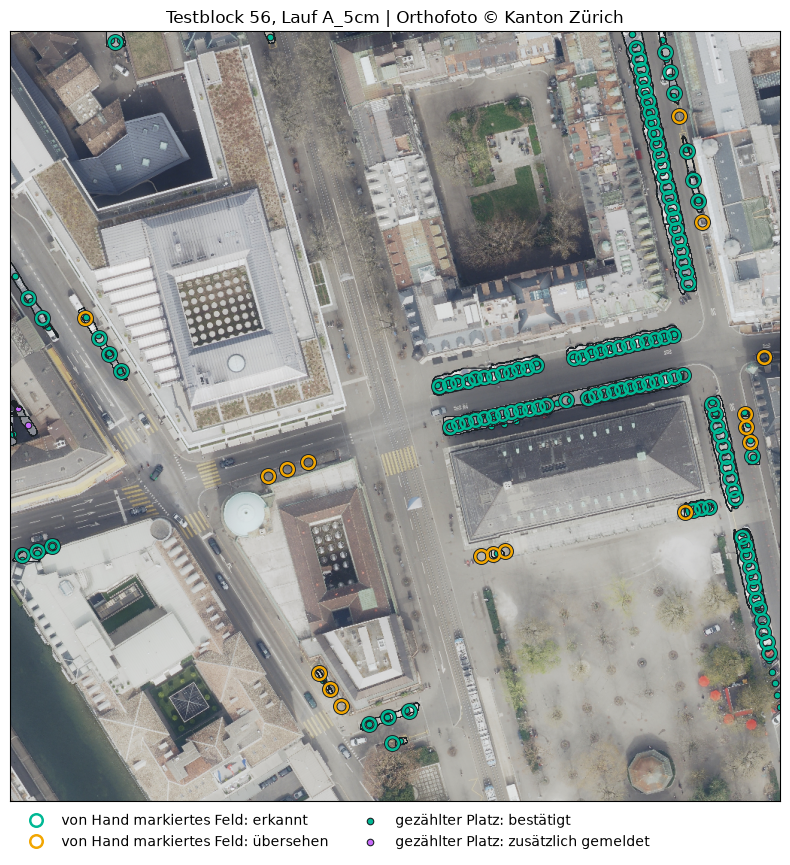

In [16]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(bild.transpose(1, 2, 0), extent=[links, rechts, unten, oben])
gezaehlt = flaechen[flaechen.teil == "gezählt"]
gezaehlt.plot(ax=ax, color="white", alpha=0.42)                    # helle Fläche: was das Netz meldet
gezaehlt.boundary.plot(ax=ax, color="#1d2327", linewidth=0.8)       # dunkler Rand, damit die Fläche auch auf hellem Grund sichtbar ist
for status, farbe in [("erkannt", FARBEN["passt"]), ("übersehen", FARBEN["fehlt"])]:
    teil = felder[felder.status == status]
    ax.plot(teil.x, teil.y, "o", markersize=9, markerfacecolor="none", markeredgecolor="#1d2327", markeredgewidth=3.2)     # dunkler Rand
    ax.plot(teil.x, teil.y, "o", markersize=9, markerfacecolor="none", markeredgecolor=farbe, markeredgewidth=1.8, label=f"von Hand markiertes Feld: {status}")
for status, farbe in [("bestätigt", FARBEN["passt"]), ("zusätzlich gemeldet", FARBEN["extra"])]:
    punkte[punkte.status == status].plot(ax=ax, color=farbe, edgecolor="#1d2327", markersize=22, linewidth=0.8, label=f"gezählter Platz: {status}")
ax.set_xlim(links, rechts); ax.set_ylim(unten, oben); ax.set_xticks([]); ax.set_yticks([])
ax.set_xlabel(""); ax.set_ylabel("")                             # keine Achsenbeschriftung
ax.legend(loc="upper left", bbox_to_anchor=(0, 0), ncol=2, frameon=False)
ax.set_title(f"Testblock {block.block}, Lauf A_5cm | Orthofoto © Kanton Zürich")
fig.savefig(ABB / "13_vorschau.png", dpi=110, bbox_inches="tight")
plt.show()

**Was die Abbildung zeigt.** Helle Flächen mit dunklem Rand: was das Netz meldet und was gezählt wird. Gefüllte Punkte: die gezählten Plätze, gleichmässig auf die Flächen verteilt; grün, wenn in der Fläche ein sichtbares Feld der Ground Truth liegt, violett, wenn nicht. Ringe: die von Hand erfassten Felder; grün, wenn mindestens die Hälfte ihres Kästchens gemeldet ist, gelb, wenn nicht.

## Wörter und Zeichen im Dashboard

Das Dashboard richtet sich an Leute, die das Projekt nicht kennen. Es verwendet darum Alltagswörter. Die Namen in den Daten (`status`, `gruppe`) bleiben, wie sie sind; das Dashboard erklärt sie unter «Über diese Karte», Teil «Daten nutzen».

| Im Dashboard | In den Notebooks |
| --- | --- |
| das Programm | die Methode, das Netz |
| von Hand markiertes Parkfeld | Feld der Ground Truth |
| Prüfgebiet | Testblock (`gruppe` = `testen`) |
| Lerngebiet | Lernblock (`lernen`) |
| Einstellgebiet | Validierblock (`validieren`) |

| Zeichen | Bedeutung |
| --- | --- |
| gefüllter Punkt | Platz, den die Methode gezählt hat: grün = bestätigt, violett = zusätzlich gemeldet |
| Ring | von Hand erfasstes Feld: grün = erkannt, gelb = übersehen |
| weiss gestrichelt (Ring oder Umriss) | nicht bewertet: verdeckt, unsicher, Streifen, einzeln stehendes Feld |
| helle Fläche mit dunklem Rand | gemeldete Fläche, die gezählt wird |
| Umriss: durchgezogen, gepunktet, gestrichelt | Testblock, Lernblock, Validierblock |

Die Flächen haben mit Absicht keine der drei Farben: Die Farbe sagt nur bei Punkten und Ringen, wie der Vergleich ausgeht. «Nicht bewertet» ist gestrichelt statt grau, damit es sich nicht nur durch die Farbe unterscheidet.

## Wie man das Dashboard öffnet

- Die Datei `ergebnisse/dashboard/dashboard.html` per Doppelklick im Browser öffnen. Sie braucht eine Internetverbindung: Die Luftbilder kommen vom Kartendienst des Kantons Zürich, die Kartenbibliothek von unpkg.com.
- Der Knopf "GeoPackage" lädt die Datei des gewählten Laufs aus dem Ordner `daten` daneben. Die beiden gehören zusammen.

## Was wir gesehen haben

- Das Dashboard ist eine einzige HTML-Datei mit allen vier Läufen.
- Die Zahlen der Karte stimmen mit Notebook 12 überein (Kontrolle in Abschnitt 2).
- Die Grenzen der Karte stehen in Notebook 12 und im Dashboard unter «Über diese Karte»: keine Prüfung, Punkte sind keine einzelnen Felder, gelbe Markierungen zählen mit.
- Eine Legende erklärt jedes Zeichen; sie zeigt nur, was gerade eingeschaltet ist.